## Chronic Kidney Disease Classification — Model Comparison

In [91]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, Normalizer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA

from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

## 1. Load and inspect the authentic dataset

In [92]:
ckd = fetch_ucirepo(id=336)
X = ckd.data.features.copy()
y_df = ckd.data.targets.copy()

print("Original feature shape:", X.shape)
print("Target columns:", list(y_df.columns))
print(X.head())
print(y_df.head())



Original feature shape: (400, 24)
Target columns: ['class']
    age    bp     sg   al   su     rbc        pc         pcc          ba  \
0  48.0  80.0  1.020  1.0  0.0     NaN    normal  notpresent  notpresent   
1   7.0  50.0  1.020  4.0  0.0     NaN    normal  notpresent  notpresent   
2  62.0  80.0  1.010  2.0  3.0  normal    normal  notpresent  notpresent   
3  48.0  70.0  1.005  4.0  0.0  normal  abnormal     present  notpresent   
4  51.0  80.0  1.010  2.0  0.0  normal    normal  notpresent  notpresent   

     bgr  ...  hemo   pcv    wbcc  rbcc  htn   dm  cad  appet   pe  ane  
0  121.0  ...  15.4  44.0  7800.0   5.2  yes  yes   no   good   no   no  
1    NaN  ...  11.3  38.0  6000.0   NaN   no   no   no   good   no   no  
2  423.0  ...   9.6  31.0  7500.0   NaN   no  yes   no   poor   no  yes  
3  117.0  ...  11.2  32.0  6700.0   3.9  yes   no   no   poor  yes  yes  
4  106.0  ...  11.6  35.0  7300.0   4.6   no   no   no   good   no   no  

[5 rows x 24 columns]
  class
0   ckd



## 2. Clean raw values and prepare the target


In [93]:

X.columns = [str(c).strip() for c in X.columns]
X = X.drop(columns=["id", "Unnamed: 0"], errors="ignore")

print("Feature shape:", X.shape)
print("Target counts:")
print(y.value_counts())
print("\nMissing values:")
print(X.isnull().sum())
print("\nFeature types:")
print(X.dtypes.value_counts())


Feature shape: (400, 24)
Target counts:
class
1    250
0    150
Name: count, dtype: int64

Missing values:
age        9
bp        12
sg        47
al        46
su        49
rbc      152
pc        65
pcc        4
ba         4
bgr       44
bu        19
sc        17
sod       87
pot       88
hemo      52
pcv       71
wbcc     106
rbcc     131
htn        2
dm         2
cad        2
appet      1
pe         1
ane        1
dtype: int64

Feature types:
float64    14
str        10
Name: count, dtype: int64


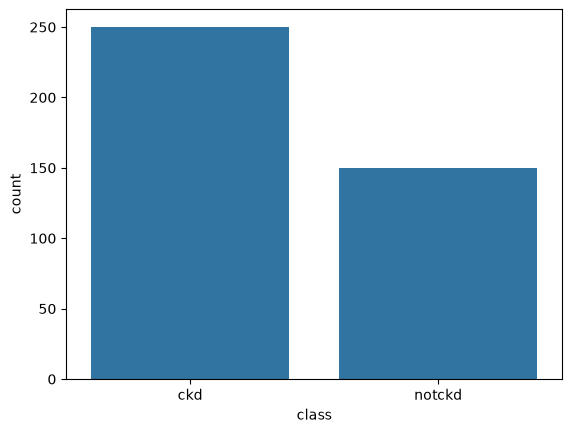

In [94]:
# Quick visualizations for the report
sns.countplot(x=y.map({0: "notckd", 1: "ckd"}))
axes[0].set_title("Target class distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")

plt.show()


## 3. Train-test split and preprocessing pipeline




In [95]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

numeric_features = X_train.select_dtypes(include="number").columns
categorical_features = X_train.select_dtypes(exclude="number").columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (320, 24)
Testing data: (80, 24)



## 4. Train and compare the six requested base classifiers


In [96]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Naive Bayes
nb = cross_validate(Pipeline([("preprocess", preprocessor), ("model", GaussianNB())]), X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1"], n_jobs=-1)

# Logistic Regression
lr = cross_validate(Pipeline([("preprocess", preprocessor), ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=42))]), X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1"], n_jobs=-1)

# SVM
svm = cross_validate(Pipeline([("preprocess", preprocessor), ("model", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42))]), X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1"], n_jobs=-1)

# Random Forest
rf = cross_validate(Pipeline([("preprocess", preprocessor), ("model", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42))]), X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1"], n_jobs=-1)

# Decision Tree
dt = cross_validate(Pipeline([("preprocess", preprocessor), ("model", DecisionTreeClassifier(class_weight="balanced", random_state=42))]), X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1"], n_jobs=-1)

# KNN
knn = cross_validate(Pipeline([("preprocess", preprocessor), ("model", KNeighborsClassifier(n_neighbors=5))]), X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1"], n_jobs=-1)

# Display results
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression", "SVM (RBF)", "Random Forest", "Decision Tree", "KNN"],
    "CV Accuracy": [nb["test_accuracy"].mean(), lr["test_accuracy"].mean(), svm["test_accuracy"].mean(), rf["test_accuracy"].mean(), dt["test_accuracy"].mean(), knn["test_accuracy"].mean()],
    "CV Precision": [nb["test_precision"].mean(), lr["test_precision"].mean(), svm["test_precision"].mean(), rf["test_precision"].mean(), dt["test_precision"].mean(), knn["test_precision"].mean()],
    "CV Recall": [nb["test_recall"].mean(), lr["test_recall"].mean(), svm["test_recall"].mean(), rf["test_recall"].mean(), dt["test_recall"].mean(), knn["test_recall"].mean()],
    "CV F1": [nb["test_f1"].mean(), lr["test_f1"].mean(), svm["test_f1"].mean(), rf["test_f1"].mean(), dt["test_f1"].mean(), knn["test_f1"].mean()]
})

results = results.sort_values("CV F1", ascending=False)
print(results.round(4))


                 Model  CV Accuracy  CV Precision  CV Recall   CV F1
3        Random Forest       0.9938        0.9902      1.000  0.9951
1  Logistic Regression       0.9938        1.0000      0.990  0.9949
2            SVM (RBF)       0.9938        1.0000      0.990  0.9949
0          Naive Bayes       0.9656        1.0000      0.945  0.9714
4        Decision Tree       0.9625        0.9750      0.965  0.9699
5                  KNN       0.9594        1.0000      0.935  0.9663


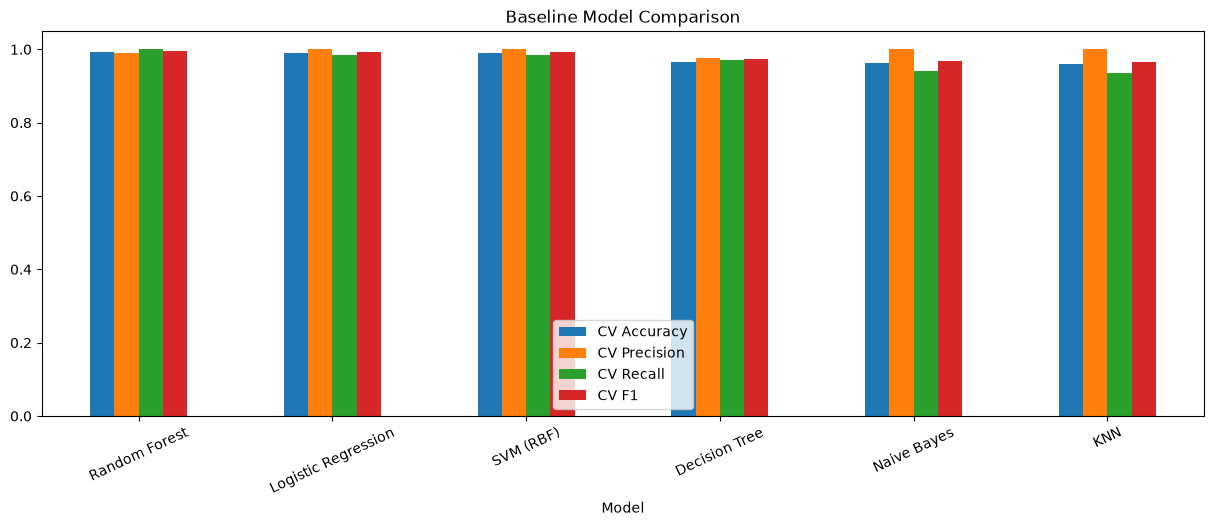

In [97]:

baseline_results.plot(
    x="Model",
    y=["CV Accuracy", "CV Precision", "CV Recall", "CV F1"],
    kind="bar",
    figsize=(15, 5)
)

plt.ylim(0, 1.05)
plt.title("Baseline Model Comparison")
plt.xticks(rotation=25)

plt.show()


## 5. Hyperparameter tuning with GridSearchCV


In [98]:

for name, model in models.items():
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])

    search = GridSearchCV(
        pipe,
        param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    print("\nModel:", name)
    print("Best CV F1:", round(search.best_score_, 4))
    print("Best Parameters:", search.best_params_)



Model: Naive Bayes
Best CV F1: 0.9714
Best Parameters: {'model__var_smoothing': 1e-11}

Model: Logistic Regression
Best CV F1: 0.995
Best Parameters: {'model__C': 1, 'model__class_weight': None, 'model__solver': 'liblinear'}

Model: SVM (RBF)
Best CV F1: 1.0
Best Parameters: {'model__C': 1, 'model__class_weight': None, 'model__gamma': 0.01}

Model: Random Forest
Best CV F1: 0.9951
Best Parameters: {'model__class_weight': None, 'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 150}

Model: Decision Tree
Best CV F1: 0.9799
Best Parameters: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': None, 'model__min_samples_leaf': 2}

Model: KNN
Best CV F1: 0.9769
Best Parameters: {'model__n_neighbors': 9, 'model__p': 1, 'model__weights': 'uniform'}



## 6. Test PCA as an optional dimensionality-reduction method



In [99]:

pca_searches = {}

pca_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("pca", "passthrough"),
    ("model", LogisticRegression(
        max_iter=3000, class_weight="balanced",
        random_state=42
    ))
])

pca_grid = {
    "pca": ["passthrough", PCA(n_components=0.95, svd_solver="full")],
    "model__C": [0.1, 1, 10]
}

search = GridSearchCV(pca_pipe, pca_grid, scoring="f1", cv=cv, n_jobs=-1)
search.fit(X_train, y_train)
pca_searches["Logistic Regression"] = search

print("Logistic Regression")
print("Best CV F1:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)


svm_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("pca", "passthrough"),
    ("model", SVC(
        kernel="rbf", class_weight="balanced",
        probability=True, random_state=42
    ))
])

svm_grid = {
    "pca": ["passthrough", PCA(n_components=0.95, svd_solver="full")],
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", 0.01]
}

search = GridSearchCV(svm_pipe, svm_grid, scoring="f1", cv=cv, n_jobs=-1)
search.fit(X_train, y_train)
pca_searches["SVM (RBF)"] = search

print("\nSVM (RBF)")
print("Best CV F1:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)


knn_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("pca", "passthrough"),
    ("model", KNeighborsClassifier())
])

knn_grid = {
    "pca": ["passthrough", PCA(n_components=0.95)],
    "model__n_neighbors": [3, 5, 7, 9],
    "model__weights": ["uniform", "distance"]
}

search = GridSearchCV(knn_pipe, knn_grid, scoring="f1", cv=cv, n_jobs=-1)
search.fit(X_train, y_train)
pca_searches["KNN"] = search

print("\nKNN")
print("Best CV F1:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)


Logistic Regression
Best CV F1: 0.9949
Best parameters: {'model__C': 1, 'pca': 'passthrough'}

SVM (RBF)
Best CV F1: 0.9975
Best parameters: {'model__C': 10, 'model__gamma': 0.01, 'pca': 'passthrough'}

KNN
Best CV F1: 0.9743
Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform', 'pca': PCA(n_components=0.95)}


## 7. Ensemble learning: Bagging and Stacking



In [100]:

# Bagging

bagging_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42
        ),
        n_estimators=25,
        max_samples=0.8,
        max_features=1.0,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    ))
])

bagging_scores = cross_validate(
    bagging_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"],
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)

print("Bagging")
print("Accuracy:", round(bagging_scores["test_accuracy"].mean(), 4))
print("Precision:", round(bagging_scores["test_precision"].mean(), 4))
print("Recall:", round(bagging_scores["test_recall"].mean(), 4))
print("F1 Score:", round(bagging_scores["test_f1"].mean(), 4))


# Stacking

stacking_model = StackingClassifier(
    estimators=[
        ("lr", Pipeline([
            ("preprocess", preprocessor),
            ("model", LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                random_state=42
            ))
        ])),
        ("svm", Pipeline([
            ("preprocess", preprocessor),
            ("model", SVC(
                kernel="rbf",
                probability=True,
                class_weight="balanced",
                random_state=42
            ))
        ])),
        ("rf", Pipeline([
            ("preprocess", preprocessor),
            ("model", RandomForestClassifier(
                n_estimators=150,
                class_weight="balanced",
                random_state=42
            ))
        ])),
        ("knn", Pipeline([
            ("preprocess", preprocessor),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ]))
    ],
    final_estimator=LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ),
    stack_method="predict_proba",
    cv=5,
    n_jobs=-1
)

stacking_scores = cross_validate(
    stacking_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1"],
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)

print("\nStacking")
print("Accuracy:", round(stacking_scores["test_accuracy"].mean(), 4))
print("Precision:", round(stacking_scores["test_precision"].mean(), 4))
print("Recall:", round(stacking_scores["test_recall"].mean(), 4))
print("F1 Score:", round(stacking_scores["test_f1"].mean(), 4))


Bagging
Accuracy: 0.9719
Precision: 0.9752
Recall: 0.98
F1 Score: 0.9775

Stacking
Accuracy: 0.9969
Precision: 1.0
Recall: 0.995
F1 Score: 0.9975


## 8. Final evaluation on the untouched test set



In [101]:

# 1. Tuned Naive Bayes
nb_model = tuned_searches["Naive Bayes"].best_estimator_
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)

print("Tuned Naive Bayes")
print("Accuracy:", round(accuracy_score(y_test, nb_pred), 4))
print("Precision:", round(precision_score(y_test, nb_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, nb_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, nb_pred, zero_division=0), 4))


# 2. Tuned Logistic Regression
lr_model = tuned_searches["Logistic Regression"].best_estimator_
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("\nTuned Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, lr_pred), 4))
print("Precision:", round(precision_score(y_test, lr_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, lr_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, lr_pred, zero_division=0), 4))


# 3. Tuned SVM
svm_model = tuned_searches["SVM (RBF)"].best_estimator_
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)

print("\nTuned SVM")
print("Accuracy:", round(accuracy_score(y_test, svm_pred), 4))
print("Precision:", round(precision_score(y_test, svm_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, svm_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, svm_pred, zero_division=0), 4))


# 4. Tuned Random Forest
rf_model = tuned_searches["Random Forest"].best_estimator_
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("\nTuned Random Forest")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, rf_pred, zero_division=0), 4))


# 5. Tuned Decision Tree
dt_model = tuned_searches["Decision Tree"].best_estimator_
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("\nTuned Decision Tree")
print("Accuracy:", round(accuracy_score(y_test, dt_pred), 4))
print("Precision:", round(precision_score(y_test, dt_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, dt_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, dt_pred, zero_division=0), 4))


# 6. Tuned KNN
knn_model = tuned_searches["KNN"].best_estimator_
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

print("\nTuned KNN")
print("Accuracy:", round(accuracy_score(y_test, knn_pred), 4))
print("Precision:", round(precision_score(y_test, knn_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, knn_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, knn_pred, zero_division=0), 4))


# 7. PCA Logistic Regression
pca_lr_model = pca_searches["Logistic Regression"].best_estimator_
pca_lr_model.fit(X_train, y_train)
pca_lr_pred = pca_lr_model.predict(X_test)

print("\nPCA Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, pca_lr_pred), 4))
print("Precision:", round(precision_score(y_test, pca_lr_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, pca_lr_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, pca_lr_pred, zero_division=0), 4))


# 8. PCA SVM
pca_svm_model = pca_searches["SVM (RBF)"].best_estimator_
pca_svm_model.fit(X_train, y_train)
pca_svm_pred = pca_svm_model.predict(X_test)

print("\nPCA SVM")
print("Accuracy:", round(accuracy_score(y_test, pca_svm_pred), 4))
print("Precision:", round(precision_score(y_test, pca_svm_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, pca_svm_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, pca_svm_pred, zero_division=0), 4))


# 9. PCA KNN
pca_knn_model = pca_searches["KNN"].best_estimator_
pca_knn_model.fit(X_train, y_train)
pca_knn_pred = pca_knn_model.predict(X_test)

print("\nPCA KNN")
print("Accuracy:", round(accuracy_score(y_test, pca_knn_pred), 4))
print("Precision:", round(precision_score(y_test, pca_knn_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, pca_knn_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, pca_knn_pred, zero_division=0), 4))


# 10. Bagging
bagging_model.fit(X_train, y_train)
bagging_pred = bagging_model.predict(X_test)

print("\nBagging")
print("Accuracy:", round(accuracy_score(y_test, bagging_pred), 4))
print("Precision:", round(precision_score(y_test, bagging_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, bagging_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, bagging_pred, zero_division=0), 4))


# 11. Stacking
stacking_model.fit(X_train, y_train)
stacking_pred = stacking_model.predict(X_test)

print("\nStacking")
print("Accuracy:", round(accuracy_score(y_test, stacking_pred), 4))
print("Precision:", round(precision_score(y_test, stacking_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, stacking_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, stacking_pred, zero_division=0), 4))


Tuned Naive Bayes
Accuracy: 0.975
Precision: 1.0
Recall: 0.96
F1 Score: 0.9796

Tuned Logistic Regression
Accuracy: 0.975
Precision: 1.0
Recall: 0.96
F1 Score: 0.9796

Tuned SVM
Accuracy: 0.975
Precision: 1.0
Recall: 0.96
F1 Score: 0.9796

Tuned Random Forest
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Tuned Decision Tree
Accuracy: 0.9875
Precision: 1.0
Recall: 0.98
F1 Score: 0.9899

Tuned KNN
Accuracy: 0.9625
Precision: 1.0
Recall: 0.94
F1 Score: 0.9691

PCA Logistic Regression
Accuracy: 0.975
Precision: 1.0
Recall: 0.96
F1 Score: 0.9796

PCA SVM
Accuracy: 0.975
Precision: 1.0
Recall: 0.96
F1 Score: 0.9796

PCA KNN
Accuracy: 0.9625
Precision: 1.0
Recall: 0.94
F1 Score: 0.9691

Bagging
Accuracy: 0.9875
Precision: 0.9804
Recall: 1.0
F1 Score: 0.9901

Stacking
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


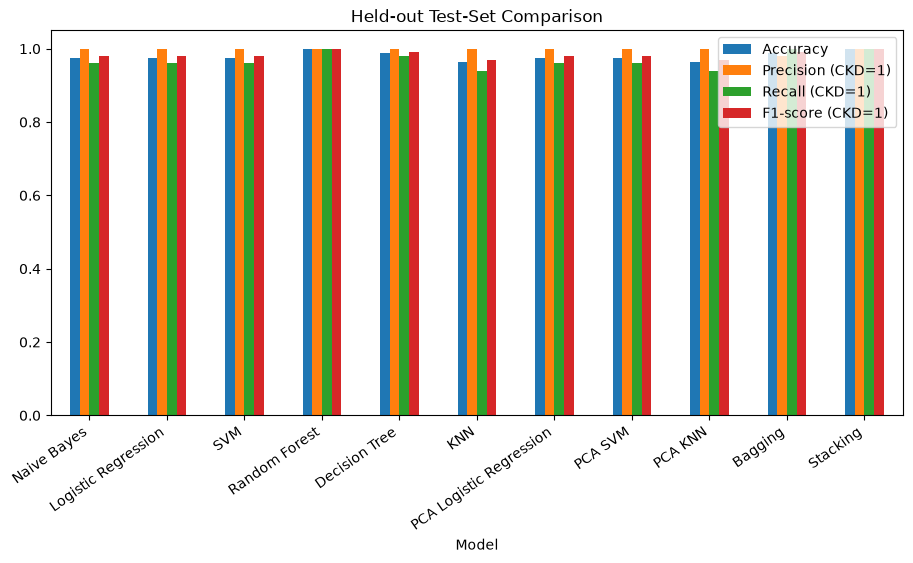

In [102]:

test_results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (CKD=1)": precision_score(y_test, pred, zero_division=0),
        "Recall (CKD=1)": recall_score(y_test, pred, zero_division=0),
        "F1-score (CKD=1)": f1_score(y_test, pred, zero_division=0)
    }
    for name, pred in {
        "Naive Bayes": nb_pred,
        "Logistic Regression": lr_pred,
        "SVM": svm_pred,
        "Random Forest": rf_pred,
        "Decision Tree": dt_pred,
        "KNN": knn_pred,
        "PCA Logistic Regression": pca_lr_pred,
        "PCA SVM": pca_svm_pred,
        "PCA KNN": pca_knn_pred,
        "Bagging": bagging_pred,
        "Stacking": stacking_pred
    }.items()
])

test_results.plot(
    x="Model",
    y=["Accuracy", "Precision (CKD=1)", "Recall (CKD=1)", "F1-score (CKD=1)"],
    kind="bar",
    figsize=(11, 5)
)

plt.ylim(0, 1.05)
plt.title("Held-out Test-Set Comparison")
plt.xticks(rotation=35, ha="right")

plt.show()


## 9. Confusion matrix and classification report for the best model

In [103]:
test_results = test_results.sort_values("F1-score (CKD=1)", ascending=False)

print(test_results.round(4))

print("Best Model:", test_results.iloc[0]["Model"])

                      Model  Accuracy  Precision (CKD=1)  Recall (CKD=1)  \
3             Random Forest    1.0000             1.0000            1.00   
10                 Stacking    1.0000             1.0000            1.00   
9                   Bagging    0.9875             0.9804            1.00   
4             Decision Tree    0.9875             1.0000            0.98   
0               Naive Bayes    0.9750             1.0000            0.96   
1       Logistic Regression    0.9750             1.0000            0.96   
2                       SVM    0.9750             1.0000            0.96   
6   PCA Logistic Regression    0.9750             1.0000            0.96   
7                   PCA SVM    0.9750             1.0000            0.96   
5                       KNN    0.9625             1.0000            0.94   
8                   PCA KNN    0.9625             1.0000            0.94   

    F1-score (CKD=1)  
3             1.0000  
10            1.0000  
9             0.99